<a name='T'>

<p style="padding: 20px;
          background-color: black;
          font-family: computermodern;
          color: white;
          font-size: 200%;
          text-align: center;
          border-radius: 40px 20px;
          ">Assisted Coding Challenge #1 💙 Floor of MEX (Hard Version)<br>
          </p>
<p style="font-family: computermodern;
          color: #000000;
          font-size: 175%;
          text-align: center;
          ">Programming Puzzle, "Expert" Difficulty (1800 Elo)
             </p>

Welcome to my **Assisted Coding series**! Tougher problems, with a small AI assistant by your side: it can explain, give hints and review your code, but the solving is up to you.

Today, I propose a challenging problem: the [Floor of MEX (Hard Version)](https://codeforces.com/problemset/problem/2262/A2) puzzle from CodeForces. Let's dive into it!

<a id="TOC"></a>

<div style="background-color: #e3f2fd; border-left: 10px solid #2196f3; padding: 20px; margin-bottom: 20px; border-radius: 8px; box-shadow: 0 2px 5px rgba(0,0,0,0.1);">
    <h3 style="color: #1976d2;">Table of Contents</h3>
    <ul style="list-style-type: none;">
        <li><a href="#s1" style="color: #1565c0;"><strong>1. Instructions</strong></a></li>
        <li><a href="#s2" style="color: #1565c0;"><strong>2. Input and Output</strong></a></li>
        <li><a href="#s3" style="color: #1565c0;"><strong>3. Show Time!</strong></a></li>
        <li style="margin-left: 20px;"><a href="#s3a" style="color: #1565c0;">3.1 Ask the Assistant</a></li>
        <li><a href="#s4" style="color: #1565c0;"><strong>4. Evaluation</strong></a></li>
        <li><a href="#s5" style="color: #1565c0;"><strong>5. Proposed Solution</strong></a></li>
    </ul>
</div>

*Notebook by Ir. Alexandre Le Mercier.*

In [1]:
import sys
import importlib
import subprocess
from pathlib import Path

# A copy cloned by an earlier run (Kaggle keeps it for the whole session): bring it up to date.
clone_path = Path.cwd() / 'no-ai-coding-challenges'
if (clone_path / '.git').is_dir():
    if subprocess.run(['git', '-C', str(clone_path), 'pull', '-q', '--ff-only']).returncode:
        print('Could not update the repository: using the copy cloned earlier.')

# Reuse a local checkout, including when running from a nearby notebook folder.
required_files = ('utils.py', 'assistant.py', 'acc1_utils.py', 'acc1_tests.txt')
repo_path = next((
    candidate
    for parent in (Path.cwd(), *Path.cwd().parents)
    for candidate in (parent, parent / 'no-ai-coding-challenges', parent / 'No AI Coding Challenges')
    if all((candidate / name).is_file() for name in required_files)
), None)

# Kaggle (or a standalone local notebook): clone when no checkout is available.
if repo_path is None:
    repo_path = clone_path
    subprocess.run(['git', 'clone', 'https://github.com/TortueSagace/no-ai-coding-challenges.git', str(repo_path), '-q'], check=True)

repo_path = str(repo_path.resolve())
if repo_path not in sys.path:
    sys.path.insert(0, repo_path)

# Reload when this cell runs again in the same kernel, so updated files are used.
import utils, acc1_utils
importlib.reload(utils)
importlib.reload(acc1_utils)
from utils import *
from acc1_utils import *

C:\Users\Administrator\OneDrive - UGent\PhD\PhD Related Python Codes\chess-maml\chess-hispa\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<a id="s1"></a>
<div style="color: black; background-color: #E6E6FA; padding: 10px; border-left: 5px solid purple; border-radius: 5px;">  
    <h1>1. Instructions</h1>
</div>

[Back to table of contents](#TOC)

***This one is tougher, but you're not alone: a small AI assistant can answer your questions (see [section 3](#s3a)). The thinking is still yours!*** 💪

**This is the hard version of the problem. The difference between the versions is that in this version, you need to count how many sets satisfy the constraints. You can hack only if you solved all versions of this problem.**

Let $$ f(S,x)=\text{mex}\left(\left\{\left\lfloor \frac{y}{x}\right\rfloor : y\in S\right\}\right), $$ where $S$ is a set of non-negative integers and $x$ is a positive integer. $^{\text{∗}}$

Farmer John chooses a (possibly empty) subset $A\subseteq \{0,1,\ldots,n-1\}$. He then constructs an array $a$ of length $n$, where $a_k = f(A,k)$ for every $1\le k\le n$.

Bessie, being a mischievous cow, hides the set $A$. Farmer John is left only with the array $a_1,a_2,\ldots,a_n$.

Your task is to count how many sets (including the empty set) $B \subseteq \{0,1,\ldots,n-1\}$ such that $f(B,k)=a_k$ for every $1 \le k \le n$. Since the number can be very large, output it modulo $10^9+7$. **Farmer John will only give you arrays where such a $B$ exists**.

$^{\text{∗}}$$\operatorname{mex}(c)$ denotes the minimum excluded (MEX)$^{\text{∗}}$ of the collection $c$. (in this case, the minimum non-negative integer not present in the set)

<a id="s2"></a>
<div style="color: black; background-color: #E6E6FA; padding: 10px; border-left: 5px solid purple; border-radius: 5px;">  
    <h1>2. Input and Output</h1>
</div>

[Back to table of contents](#TOC)

## Input

Your function receives:
- `n` (int): the size of the universe `{0, 1, ..., n-1}` and the length of `a` (`1 ≤ n ≤ 10^4`)
- `a` (list of int): the array `a_1, ..., a_n` with `0 ≤ a_k ≤ n`, stored 0-indexed (`a[k-1]` is a_k); at least one valid set exists

## Output

Your function must return an int `count`: the number of sets B with f(B, k) = a_k for every k, modulo 10^9 + 7.

## Sample Test Cases

| n | a | Expected Output | Explanation |
|---|---|-----------------|-------------|
| 6 | `[0, 3, 2, 2, 2, 1]` | `6` | k = 1 forces 0 ∉ B; k = 5 forces 5 ∈ B; k = 2 then needs 1 ∈ B and one of {2, 3}, while 4 is free → 3 × 2 = 6 sets. |
| 5 | `[2, 1, 1, 1, 1]` | `1` | k = 1 forces 0, 1 ∈ B and 2 ∉ B; k = 2 and k = 3 forbid 3 and 4 → only {0, 1}. |
| 6 | `[1, 2, 1, 1, 1, 1]` | `1` | k = 1 forces 0 ∈ B, 1 ∉ B; k = 2 needs an element in [2, 3], k = 3 forbids 3 and k = 2 forbids 4, 5 → only {0, 2}. |

<a id="s3"></a>
<div style="color: black; background-color: #E6E6FA; padding: 10px; border-left: 5px solid purple; border-radius: 5px;">  
    <h1>3. Show Time!</h1>
</div>

[Back to table of contents](#TOC)

***Time to shine! Try solving the problem by yourself. You can do it!*** 🧠

Implement your solution in the `my_solution(n, a)` function below. The function should return `count` as described above.

**Time limit per test**: 2 seconds.

**Memory limit per test**: 256 megabytes.

In [2]:
######################### SETUP ############################

samples = [
    [6, [0, 3, 2, 2, 2, 1]],
    [5, [2, 1, 1, 1, 1]],
    [6, [1, 2, 1, 1, 1, 1]]
]

TIME_LIMIT = 2
MEMORY_LIMIT = 256e6

print(f"Loaded {len(samples)} sample test cases.")

Loaded 3 sample test cases.


In [3]:
######################### RESOLUTION ###########################

def my_solution(n, a):
    """
    Count the sets B ⊆ {0, ..., n-1} such that f(B, k) = a_k for every 1 ≤ k ≤ n, modulo 10^9 + 7.
    
    Parameters:
    -----------
    n : int
        The size of the universe {0, 1, ..., n-1} and the length of a (1 ≤ n ≤ 10^4)
    a : list of int
        The array a_1, ..., a_n with 0 ≤ a_k ≤ n, stored 0-indexed (a[k-1] is a_k); at least one valid set exists
    
    Returns:
    --------
    int : the number of sets B with f(B, k) = a_k for every k, modulo 10^9 + 7
    """
    
    # --> Your solution here! <--
    
    pass  # Remove this and return count

ℹ️ **Tips**
- Run the cell below to test your solution on the sample test cases.
- Each test case has exactly one correct answer.

In [4]:
##################### ACCURACY AND EFFICIENCY CHECK ########################

evaluate_on_samples(samples, my_solution, check_solution, TIME_LIMIT, MEMORY_LIMIT)


                        Sample Test Results                        
   # │ Input                   │ Output │         Time │ Status    
─────┼─────────────────────────┼────────┼──────────────┼───────────
   1 │ [6, [0, 3, 2, 2, 2, 1]] │ None   │      61.0 μs │ ❌ Wrong   
   2 │ [5, [2, 1, 1, 1, 1]]    │ None   │       6.1 μs │ ❌ Wrong   
   3 │ [6, [1, 2, 1, 1, 1, 1]] │ None   │       3.8 μs │ ❌ Wrong   

❌  0/3 sample tests passed
    First failure: Invalid output: function returned None. Did you run the cell containing your solution?


<a id="s3a"></a>
### 🤖 Stuck? Ask the Assistant

A small AI model that has read the statement: it explains, hints and debugs, but it won't solve the problem for you. You have **10 questions**.

**Setup (once)**
- Get a free key at [openrouter.ai/keys](https://openrouter.ai/keys).
- Save it in **one** of these two ways, depending on where you run the notebook:
    - **On Kaggle:** *Add-ons → Secrets* → add `OPENROUTER_API_KEY` → tick it for this notebook.
    - **On your computer:** put `OPENROUTER_API_KEY=...` in a `.env` file next to the notebook.
- Run the cell below.

**Use**
- `ask("Why is my solution wrong?")`: your solution cell and its sample results are sent with the question.
- `fix()` as the **last line of your solution cell**, then run that cell: the cell is replaced by a corrected version (1 question).
- `undo()`, same place: brings your version back.
- `reset()`: starts a new conversation.

**Good to know**
- It only sees the statement, the samples and your solution cell as you last ran it: rerun that cell before asking.
- Free models may log prompts: don't paste anything private.

In [ ]:
######################### AI ASSISTANT ###########################

import assistant
importlib.reload(assistant)
from assistant import ask, fix, undo, reset

assistant.start(Path(repo_path) / 'acc1_context.md', questions=10)

In [6]:
# For example:
# ask("Can you explain the second sample test case?")
# ask("Why does my solution fail on the samples?")
# Last line of your solution cell: fix()  or  fix("I think the DP is off by one")

<a id="s4"></a>
<div style="color: black; background-color: #E6E6FA; padding: 10px; border-left: 5px solid purple; border-radius: 5px;">  
    <h1>4. Evaluation</h1>
</div>

[Back to table of contents](#TOC)

Run the cell below to evaluate your solution on 300 hidden test cases. You are supposed to be already confident about your solution before doing this. Please note that in competitive programming, submitting several wrong answers to the tester results in time penalties. However, feel free to run the cell above with `evaluate_on_samples` as many times as you like!

In [7]:
##################### INTERNAL EVALUATION ########################

test_file_path = str(Path(repo_path) / 'acc1_tests.txt')

if internal_evaluation(test_file_path, my_solution, check_solution, parse_tests, TIME_LIMIT, MEMORY_LIMIT, get_input_size=get_input_size, plot_title='Floor of MEX (Hard Version)', show_estimation=True):
    print("✅ The proposed solution meets both accuracy and efficiency requirements")

  0%|          | 0/300 [00:00<?, ?it/s]

  0%|          | 0/300 [00:00<?, ?it/s]


❌  Invalid output: function returned None. Did you run the cell containing your solution?


<a id="s5"></a>
<div style="color: black; background-color: #E6E6FA; padding: 10px; border-left: 5px solid purple; border-radius: 5px;">  
    <h1>5. Proposed Solution</h1>
</div>

[Back to table of contents](#TOC)

Here is a correct solution. It doesn't necessarily mean that it is the *only* correct one.

<details>
<summary><strong>💡 Click to reveal Solution Explanation</strong></summary>

<div style="color: black; background-color: #cce5ff; padding: 10px; border-left: 5px solid #3399ff; border-radius: 5px; margin-top: 10px;">
    <strong>Key insight:</strong> f(B, k) = aₖ splits {0, …, n−1} into blocks of length k and says two things: each of the first aₖ blocks contains an element of B, and block number aₖ contains none. So every aₖ gives some <em>forbidden</em> positions and some intervals that B must <em>hit</em>. Since a hit interval must start below n, there are at most ⌈n/k⌉ of them for each k: O(n log n) intervals in total (harmonic sum).<br><br>
    <strong>Strategy:</strong>
    <ol>
        <li>For each k, mark the block [aₖ·k, aₖ·k + k − 1] as forbidden (difference array). For each j &lt; aₖ, record the interval [j·k, min(j·k + k − 1, n − 1)], keeping only need[r], the largest left end among the intervals that end at r.</li>
        <li>Sweep the positions from left to right. ways[i] counts the valid choices of B ∩ [0, i] whose largest element is i, plus one "nothing chosen yet" state. A position that isn't forbidden can be chosen after any still-valid state: a prefix sum gives that total in O(1).</li>
        <li>After position r, every interval [l, r] must contain the largest element chosen so far, so the states whose largest element is below need[r] are dropped: a pointer <code>low</code> only moves right.</li>
        <li>The answer is the sum of the states that are still valid at the end.</li>
    </ol>
    <strong>Why it works:</strong> an interval [l, r] contains an element of B exactly when the largest element of B that is ≤ r is at least l, and that is what the pointer checks when the sweep reaches r. A dropped state can never become valid again, because later choices only add larger elements. Forbidden positions are simply never chosen, so every counted set satisfies all the constraints, and each set is counted once, through its largest element.
</div>

</details><br>

The time complexity of this solution is $\mathcal O(n \log n)$ and its space complexity is $\mathcal O(n)$.

In [8]:
######################### PROPOSED SOLUTION ###########################

def proposed_solution(n, a):
    MOD = 10**9 + 7

    # a_k = m means: each block [j*k, j*k + k - 1] with j < m contains an element of B,
    # and the block [m*k, m*k + k - 1] contains none.
    need = [-1] * n      # need[r]: largest l such that [l, r] must contain an element of B
    diff = [0] * (n + 1)  # difference array of the forbidden positions
    for k in range(1, n + 1):
        m = a[k - 1]
        for j in range(m):
            l = j * k
            r = min(l + k - 1, n - 1)
            need[r] = max(need[r], l)
        if m * k < n:
            diff[m * k] += 1
            diff[min(m * k + k, n)] -= 1

    # ways[i + 1]: number of valid choices of B ∩ [0, i] whose largest element is i
    # ways[0]: the empty choice (nothing taken yet). prefix[t] = ways[0] + ... + ways[t - 1].
    ways = [0] * (n + 1)
    ways[0] = 1
    prefix = [0] * (n + 2)
    prefix[1] = 1
    low = 0       # states ways[0 .. low-1] already broke a "must contain" interval
    forbidden = 0
    for i in range(n):
        forbidden += diff[i]
        if forbidden == 0:
            # take i: the previous largest element can be any still-valid state
            ways[i + 1] = (prefix[i + 1] - prefix[low]) % MOD
        prefix[i + 2] = (prefix[i + 1] + ways[i + 1]) % MOD
        if need[i] >= 0:
            # every interval ending at i must contain the largest element chosen so far
            low = max(low, need[i] + 1)

    return (prefix[n + 1] - prefix[low]) % MOD


Testing proposed solution on hidden tests:


  0%|          | 0/300 [00:00<?, ?it/s]

 14%|█▍        | 43/300 [00:00<00:00, 417.98it/s]

 29%|██▉       | 88/300 [00:00<00:00, 434.83it/s]

 45%|████▍     | 134/300 [00:00<00:00, 430.02it/s]

 60%|█████▉    | 179/300 [00:00<00:00, 415.49it/s]

 75%|███████▌  | 225/300 [00:00<00:00, 412.27it/s]

 95%|█████████▍| 284/300 [00:00<00:00, 455.51it/s]

100%|██████████| 300/300 [00:00<00:00, 422.92it/s]

✅  All 300 tests passed!


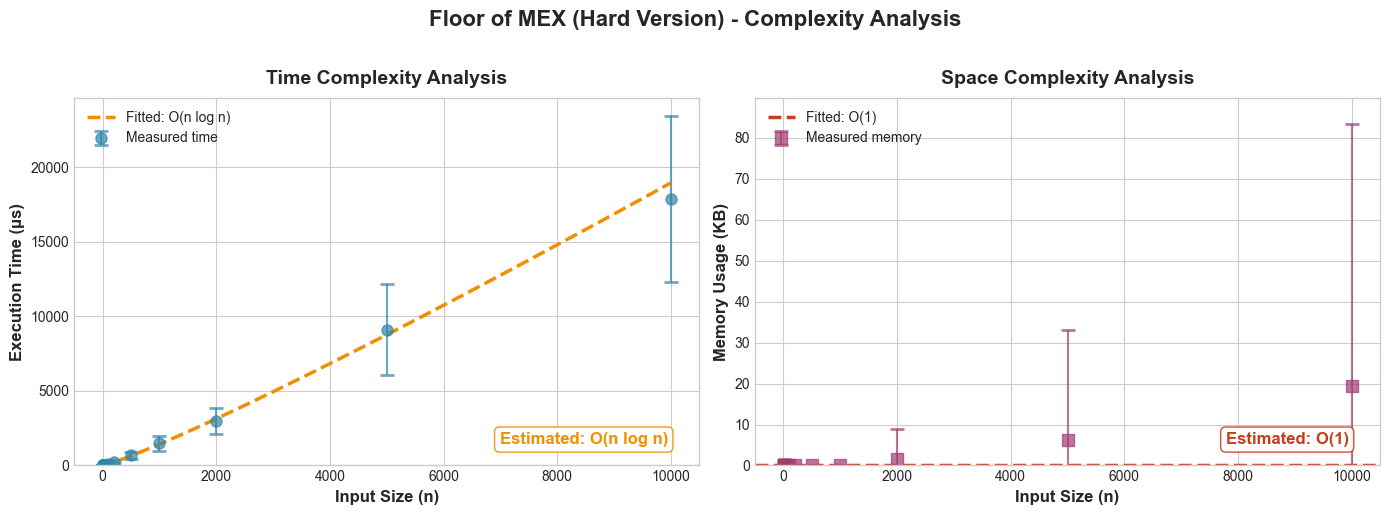


📊 Estimated Time Complexity: O(n log n)
📊 Estimated Space Complexity: O(1)
✅ The proposed solution meets both accuracy and efficiency requirements


In [9]:
##################### VERIFY PROPOSED SOLUTION ########################

print("\nTesting proposed solution on hidden tests:")
if internal_evaluation(test_file_path, proposed_solution, check_solution, parse_tests, TIME_LIMIT, MEMORY_LIMIT, get_input_size=get_input_size, plot_title='Floor of MEX (Hard Version)', show_estimation=True):
    print("✅ The proposed solution meets both accuracy and efficiency requirements")

<p style="padding: 20px;
          background-color: green;
          font-family: computermodern;
          color: white;
          font-size: 200%;
          text-align: center;
          border-radius: 40px 20px;
          ">Thank you! If you found this useful, please upvote 👍</p>